In [4]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import cv2
from PIL import Image

# спільний код заняття 6: дані VisDrone, завантаження моделей, метрики, малювання
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'lessons' / '06-zero-shot-segmentation').is_dir())
sys.path.insert(0, str(REPO / 'lessons' / '06-zero-shot-segmentation'))
import panels as P

GDINO, SAM2 = 'gdino-base', 'sam2.1-large' # 'sam2.1-small'
hf = P.setup_hf(sam=[SAM2], ov=[GDINO])        # офлайн, якщо ваги вже завантажено
DEVICE = P.pick_device(None)                   # cuda / mps / cpu
GPU = P.gpu_name(DEVICE)
# обсяг обчислень: на CPU Grounding DINO — секунди на кадр, SAM 2 — сотні мс на об'єкт, тож ноутбук сам його зменшує
CPU = DEVICE == 'cpu'
N_DEV, N_TEST = (10, 20) if CPU else (15, 30)  # кадрів DET-val для вибору промпта і для чесного заміру
STRIDE = 4 if CPU else 2                       # кадри кліпу: той самий відрізок польоту, на CPU — удвічі рідше
N_OBJ_COST = [1, 2, 4, 8] if CPU else [1, 2, 4, 8, 16]   # кількість об'єктів для заміру вартості в 4.2
OUT_DIR = Path('outputs'); OUT_DIR.mkdir(exist_ok=True)
pd.set_option('display.precision', 3)
print(f'HF: {hf} | {DEVICE}: {GPU}')


def check(ok, good, bad):
    print(('✅ ' + good) if ok else ('❌ ' + bad))

HF: offline | cpu: CPU


кліп: 30 кадрів 1904×1071, треків машин: 43, на кадрі 0: 28
DET-val: dev 10 кадрів, test 20 кадрів


Loading weights: 100%|██████████| 1182/1182 [00:00<00:00, 25269.34it/s]


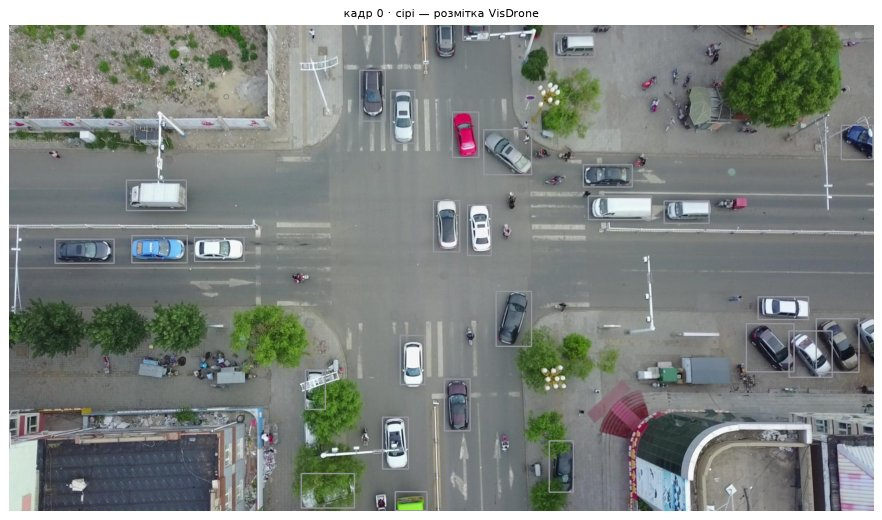

In [6]:
SEQ, START = 'uav0000305_00000_v', 60
N_FRAMES = 120 // STRIDE                          # кадри 60…178: 60 кадрів на GPU, 30 на CPU
clip = P.make_clip(SEQ, START, N_FRAMES, STRIDE, OUT_DIR / 'frames')
gt = P.clip_gt(clip, P.vid_annotations(SEQ))      # розмітка у координатах кліпу: k (кадр), tid (трек), бокс, occ
W, H = clip.size
T = len(clip.frame_ids)
key = clip.read(0)                                # ключовий кадр — на ньому працює детектор
gt0 = gt[gt.k == 0][['x0', 'y0', 'x1', 'y1']].values
print(f'кліп: {T} кадрів {W}×{H}, треків машин: {gt.tid.nunique()}, на кадрі 0: {len(gt0)}')

DEV = P.det_items(N_DEV, seed=0, offset=0)        # обираємо промпт
TEST = P.det_items(N_TEST, seed=0, offset=N_DEV)  # лише міряємо: інші кадри тієї самої перестановки
print(f'DET-val: dev {len(DEV)} кадрів, test {len(TEST)} кадрів')

gd = P.GDino(GDINO, DEVICE)                       # processor і модель Grounding DINO з transformers
proc, model = gd.proc, gd.model
P.show_row([P.draw_boxes(key, gt0, color=(150, 150, 160), thick=2)], ['кадр 0 · сірі — розмітка VisDrone'], size=10)

боксів 34: збіглись з розміткою 24, зайвих 10, пропущено 4 з 28


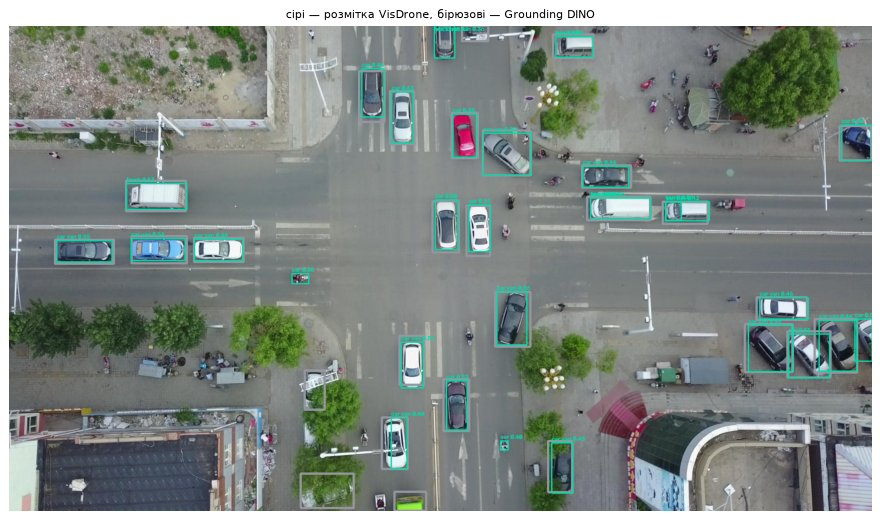

✅ знайдено 24 з 28 машин


In [7]:
PROMPT = 'car . truck . bus . van .'
BOX_THR, TEXT_THR = 0.35, 0.25                    # значення зі слайда «Механіка текстового промпта»

def detect(img, prompt, box_thr=BOX_THR, text_thr=TEXT_THR):
    inp = proc(images=Image.fromarray(img), text=prompt, return_tensors='pt').to(DEVICE)
    with torch.inference_mode():
        out = model(**inp)
    r = proc.post_process_grounded_object_detection(
        out,
        inp["input_ids"],
        threshold=box_thr,
        text_threshold=text_thr,
        target_sizes=[img.shape[:2]],
    )[0]   # TODO 1.2: бокси з порогами box_thr і text_thr у розмірі кадру img
    
    boxes = r['boxes'].float().cpu().numpy().reshape(-1, 4)
    names = [str(t) for t in (r['text_labels'] if 'text_labels' in r else r['labels'])][:len(boxes)]
    classes = [c.strip() for c in prompt.replace(',', '.').split('.') if c.strip()]
    labels = np.array([P.phrase_to_class(t, classes) for t in names], int).reshape(-1)
    return P.Dets(boxes, r['scores'].float().cpu().numpy()[:len(boxes)], labels, names)

d_key = P.detect_tiled(lambda im: detect(im, PROMPT), key)[0]
r = P.match_pr(d_key.boxes, gt0)
print(f'боксів {len(d_key)}: збіглись з розміткою {r["tp"]}, зайвих {r["fp"]}, пропущено {r["fn"]} з {len(gt0)}')
vis = P.draw_boxes(P.draw_boxes(key, gt0, color=(150, 150, 160), thick=3), d_key.boxes,
                   [f'{n} {s:.2f}' for n, s in zip(d_key.names, d_key.scores)], thick=2, font=0.45)
P.show_row([vis], ['сірі — розмітка VisDrone, бірюзові — Grounding DINO'], size=10)
check(len(d_key) > 0 and r['tp'] >= 0.5 * len(gt0), f'знайдено {r["tp"]} з {len(gt0)} машин',
      'боксів немає або знайдено менше половини машин — перевірте пороги й target_sizes')

при d_key = detect(key, PROMPT)
результат: боксів 26: збіглись з розміткою 24, зайвих 2, пропущено 4 з 28

при d_key = P.detect_tiled(lambda im: detect(im, PROMPT), key)[0]
результат: боксів 34: збіглись з розміткою 24, зайвих 10, пропущено 4 з 28

в обох випадках: знайдено 24 з 28 машин

на цих даних кількість боксів збільшилася, але це +8 зайвих 

In [8]:
PROMPTS = {
    'базовий': 'car . truck . bus . van .',
    'кома замість крапки': 'car, truck, bus, van',
    'ракурс зверху + синонім': (
        'car seen from above . '
        'truck . pickup truck . bus . van .'
    ),# TODO 1.3а: щонайменше одне власне формулювання, 'назва': 'промпт',
}

def pr_on(items, prompt):
    rows = []
    for path, g in items:
        d = detect(P.imread_rgb(path), prompt)
        rows.append(P.match_pr(d.boxes, g.boxes[np.isin(g.cats, P.VEHICLES)], ignore=g.ignore))
    p, r = P.pr_table(rows)
    return {'precision': p, 'recall': r, 'F1': 2 * p * r / max(p + r, 1e-9)}


dev = pd.DataFrame({name: pr_on(DEV, p) for name, p in PROMPTS.items()}).T
display(dev)


,precision,recall,F1
базовий,0.902,0.327,0.480
кома замість крапки,0.000,0.000,0.000
ракурс зверху + синонім,0.978,0.131,0.231


In [9]:
BEST = 'базовий'   # TODO 1.3б: назва промпта з найкращим F1 на dev, наприклад 'базовий'

In [10]:
ok_13 = len(PROMPTS) >= 3 and BEST == dev.F1.idxmax()
check(ok_13, f'на dev обрано «{BEST}»', 'потрібно 3+ промпти, а BEST — назва рядка з найбільшим F1 у таблиці dev')
if ok_13:
    test = pd.DataFrame({name: pr_on(TEST, p) for name, p in PROMPTS.items()}).T
    report = pd.concat({f'dev ({len(DEV)} кадрів)': dev, f'test ({len(TEST)} кадрів)': test}, axis=1)
    display(report.style.format('{:.2f}').apply(lambda s: ['font-weight: bold' if s.name == BEST else '' for _ in s], axis=1))
    PROMPT = PROMPTS[BEST]
    print(f'далі працюємо з промптом «{BEST}»: {PROMPT!r}')

✅ на dev обрано «базовий»


далі працюємо з промптом «базовий»: 'car . truck . bus . van .'


до фільтра:    26 боксів, TP 24, FP 2
після фільтра: 16 боксів, TP 15, FP 1


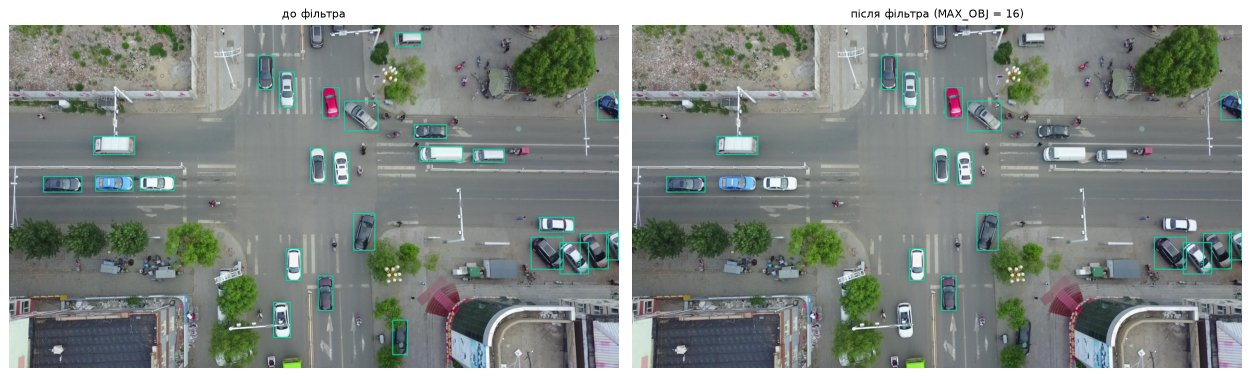

✅ 16 боксів, з них 15 — справжні машини


In [11]:
MIN_SIDE, MAX_AREA_FRAC, MIN_SCORE = 8, 0.05, 0.4
MAX_OBJ = 16   # TODO 2.1б: від 4 до 32


def filter_boxes(d):
    w, h = d.boxes[:, 2] - d.boxes[:, 0], d.boxes[:, 3] - d.boxes[:, 1]
    ok = (
        (np.minimum(w, h) >= MIN_SIDE)
        & (w * h <= MAX_AREA_FRAC * W * H)
        & (d.scores >= MIN_SCORE)
    )   # TODO 2.1а: умова на сторону, площу й score
    
    d = P.nms(d.take(np.flatnonzero(ok)), 0.6, class_aware=False)
    keep = []                                       # від більших до менших: вкладений бокс — частина об'єкта
    
    for i in np.argsort(
        -(d.boxes[:, 2] - d.boxes[:, 0]) 
        * (d.boxes[:, 3] - d.boxes[:, 1])
    ):
        if not keep or P.box_ios(d.boxes[i], d.boxes[keep]).max() < 0.8:
            keep.append(i)
    d = d.take(np.array(keep, int))
    return d.take(np.argsort(-d.scores)[:MAX_OBJ])


d_key = detect(key, PROMPT)
boxes = filter_boxes(d_key)
r0, r1 = P.match_pr(d_key.boxes, gt0), P.match_pr(boxes.boxes, gt0)
print(f'до фільтра:    {len(d_key):2d} боксів, TP {r0["tp"]}, FP {r0["fp"]}')
print(f'після фільтра: {len(boxes):2d} боксів, TP {r1["tp"]}, FP {r1["fp"]}')
w_, h_ = boxes.boxes[:, 2] - boxes.boxes[:, 0], boxes.boxes[:, 3] - boxes.boxes[:, 1]
P.show_row([P.draw_boxes(key, d_key.boxes, thick=2), P.draw_boxes(key, boxes.boxes, thick=2)],
           ['до фільтра', f'після фільтра (MAX_OBJ = {MAX_OBJ})'], size=7)
check(4 <= MAX_OBJ <= 32 and 0 < len(boxes) <= MAX_OBJ and (np.minimum(w_, h_) >= MIN_SIDE).all()
      and (w_ * h_ <= MAX_AREA_FRAC * W * H).all() and (boxes.scores >= MIN_SCORE).all() and r1['tp'] >= 0.8 * len(boxes)
      and r1['tp'] >= 0.6 * min(r0['tp'], MAX_OBJ),          # фільтр не викидає більшість справжніх машин
      f'{len(boxes)} боксів, з них {r1["tp"]} — справжні машини',
      'фільтр пропустив бокс, що порушує умову, викинув більшість справжніх машин або MAX_OBJ поза 4–32 '
      '— перевірте умову ok')

масок 16, predicted_iou: медіана 0.96, мін 0.93; частка пікселів маски всередині свого боксу: 100%


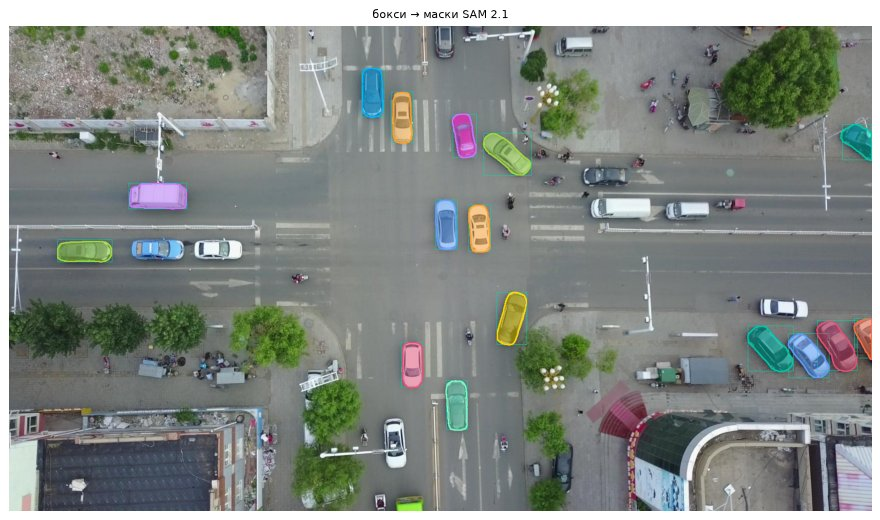

✅ маски побудовано


In [12]:
pred = P.load_sam2_image(SAM2, DEVICE)
with torch.inference_mode(), P.autocast(DEVICE):
    pred.set_image(key)   # TODO 2.2: енкодер — раз на кадр
    masks, iou, _ = pred.predict(
        box=boxes.boxes,
        multimask_output=False
    )   # TODO 2.2: усі бокси одним викликом, одна маска на бокс

masks = np.asarray(masks).reshape(len(boxes), H, W) > 0
iou = np.asarray(iou).ravel()
inside = np.mean([m[int(b[1]):int(np.ceil(b[3])), int(b[0]):int(np.ceil(b[2]))].sum() / max(m.sum(), 1)
                  for m, b in zip(masks, boxes.boxes)])
print(f'масок {len(masks)}, predicted_iou: медіана {np.median(iou):.2f}, мін {iou.min():.2f}; '
      f'частка пікселів маски всередині свого боксу: {inside:.0%}')
P.show_row([P.overlay_masks(P.draw_boxes(key, boxes.boxes, thick=1), list(masks))], ['бокси → маски SAM 2.1'], size=10)
check(len(masks) == len(boxes) and np.median(iou) >= 0.7 and inside >= 0.9,
      'маски побудовано', 'масок не стільки, скільки боксів, або вони не в боксах — перевірте predict(box=...)')

# Частина 3 · Поширення по відео

## 3.1 · SAM 2: маски по всьому кліпу (≈ 15 хв)
SAM 2 обробляє кадри потоком і тримає **банк пам'яті**: кілька останніх кадрів, кадри з промптами й «вказівники»
на об'єкти. Так зберігається ідентичність, а голова оклюзії прибирає маску, коли об'єкта не видно (слайд
«SAM 2: архітектура з пам'яттю»). Код повторює слайд «Композиція в 15 рядках»: `init_state` → промпти → `propagate_in_video`.

Функція `propagate` уже написана; усі промпти — і на кадрі 0, і корекції в кроці 3.2 — йдуть через `add_box`.

**TODO 3.1.** Допишіть `add_box`: бокс `box` для об'єкта `obj` на кадрі `k`.

*Підказка:* `vp.add_new_points_or_box(state, frame_idx=..., obj_id=..., box=...)`.

propagate in video: 100%|██████████| 30/30 [16:13<00:00, 32.45s/it]


,кадрів,"IoU, де видно","втрачено, де видно","маска, де об'єкт сховано / пішов","перескок на сусіда, кадрів"
obj 0 / трек 29,30,0.89,0,13/23,0
obj 1 / трек 15,30,0.792,0,0/9,0
obj 2 / трек 17,30,0.756,0,1/16,0
obj 3 / трек 5,30,0.598,6,1/9,0
obj 4 / трек 0,30,0.708,2,1/5,0
obj 5 / трек 13,30,0.854,0,3/23,0
obj 6 / трек 18,30,0.805,0,1/9,0
obj 7 / трек 20,30,0.782,0,2/2,0
obj 9 / трек 39,30,0.814,0,0/4,0
obj 10 / трек 31,30,0.765,2,5/10,0


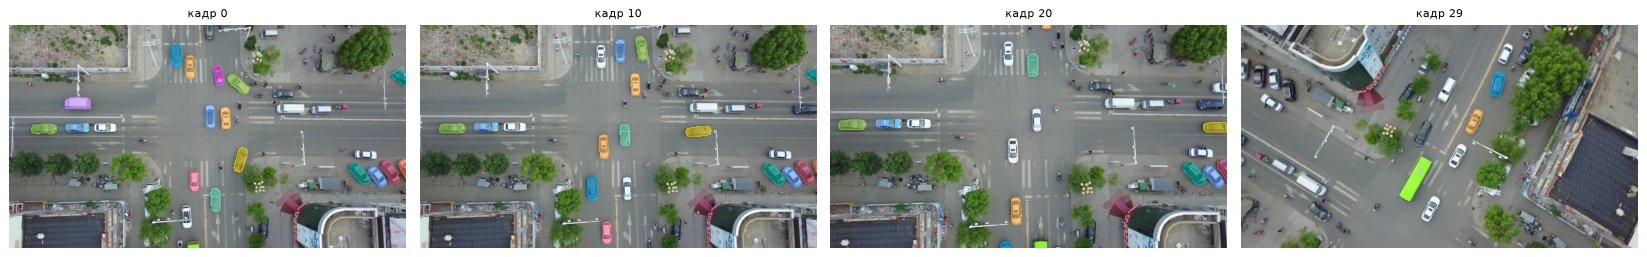

✅ 15 об'єктів ведуться, медіанний IoU 0.80


In [13]:
vp = P.load_sam2_video(SAM2, DEVICE)


def add_box(state, k, obj, box):
    vp.add_new_points_or_box(
        state,
        frame_idx=k,
        obj_id=obj,
        box=box
    )   # TODO 3.1: бокс об'єкта obj на кадрі k


def propagate(boxes0, corrections=None, on_frame=None):
    # boxes0 — бокси на кадрі 0; corrections = {кадр: {об'єкт: бокс}} — промпти в середині ролика.
    # on_frame(k, ids, маски) — для експорту в кроці 4.1. Повертає P.VideoRun: бокси й площі масок по кадрах, мс.
    n = len(boxes0)
    track = {o: np.full((T, 4), np.nan, np.float32) for o in range(n)}
    area = {o: np.zeros(T, np.float32) for o in range(n)}
    small, ms = {}, []
    with torch.inference_mode(), P.autocast(DEVICE):
        state = vp.init_state(video_path=str(clip.dir), offload_video_to_cpu=True)
        for o, b in enumerate(boxes0):
            add_box(state, 0, o, np.asarray(b, np.float32))
        for k, objs in (corrections or {}).items():
            for o, b in objs.items():
                add_box(state, int(k), int(o), np.asarray(b, np.float32))
        it = iter(vp.propagate_in_video(state))
        while True:
            with P.timed(ms):
                try:
                    k, ids, logits = next(it)
                except StopIteration:
                    break
                m = (logits[:, 0] > 0).cpu().numpy()             # (об'єктів, H, W)
            small[k] = {}
            for j, o in enumerate(int(i) for i in ids):
                area[o][k] = m[j].sum()
                small[k][o] = m[j][::4, ::4]
                b = P.mask_to_box(m[j])
                if b is not None:
                    track[o][k] = b
            if on_frame is not None:
                on_frame(k, [int(i) for i in ids], m)
        vp.reset_state(state)
    return P.VideoRun(track, area, small, ms[:-1], 0.0)


run = propagate(boxes.boxes)
# кожен об'єкт — з «своїм» GT-треком на кадрі 0; далі покадрово: IoU зі своїм, втрата, перескок на сусіда
M = P.box_iou(boxes.boxes, gt0)
tids0 = gt[gt.k == 0].tid.values
match = {o: int(tids0[M[o].argmax()]) for o in range(len(boxes)) if M[o].max() >= 0.5}
ev = {o: P.track_eval(run.boxes[o], gt, t) for o, t in match.items()}
summary = P.summarize_tracks({f'obj {o} / трек {t}': ev[o] for o, t in match.items()})
display(summary)
ks = [0, T // 3, 2 * T // 3, T - 1]
P.show_row([P.overlay_masks(clip.read(k), [run.small[k][o] for o in run.objs], ids=run.objs) for k in ks],
           [f'кадр {k}' for k in ks], size=4.6, ncols=4)
iou_vis = pd.to_numeric(summary['IoU, де видно']).median()
check(len(match) >= 0.5 * len(boxes) and iou_vis >= 0.6, f'{len(match)} об\'єктів ведуться, медіанний IoU {iou_vis:.2f}',
      'маски не поширились — перевірте add_box: frame_idx, obj_id і box')

- кількість обєктів що ведуться зменшилася на 1, стало 14
- збільшилися втрати з видимих обєктів з 9 на 13: +4 
- перескоків на сусідід не стало. було 6, зараз 0